# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [5]:
%pip install plotly nbformat
import plotly.io as pio
pio.renderers.default = "notebook_connected"

In [10]:
import os, pandas as pd

print("Working dir:", os.getcwd())

found = None
for root, dirs, files in os.walk('/'):
    if root.startswith(('/proc', '/sys', '/lib', '/usr')):
        continue
    if 'co2_emissions.csv' in files:
        found = os.path.join(root, 'co2_emissions.csv')
        break

print("Found at:", found)
df = pd.read_csv(found)
print(df.shape)

Working dir: /drive
Found at: /drive/notebooks/co2_emissions.csv
(345, 5)


In [11]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: <StringArray>
[ 'United States',          'China',          'India',        'Germany',
 'United Kingdom',         'France',         'Brazil',          'Japan',
         'Canada',      'Australia',    'South Korea',         'Russia',
   'South Africa',         'Mexico',      'Indonesia']
Length: 15, dtype: str

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


---
## Task — Multi-Series Line Chart with Highlight

**What to build:** A line chart showing CO2 emissions over time for **all Asian countries** in the dataset, with one country highlighted.

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

In [14]:
%pip install plotly nbformat

In [15]:
import os
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)

# Finds the CSV wherever the kernel put it
found = None
for root, dirs, files in os.walk('/'):
    if root.startswith(('/proc', '/sys', '/lib', '/usr')):
        continue
    if 'co2_emissions.csv' in files:
        found = os.path.join(root, 'co2_emissions.csv')
        break

df = pd.read_csv(found)
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())

Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


Asian countries: ['China', 'India', 'Indonesia', 'Japan', 'South Korea']


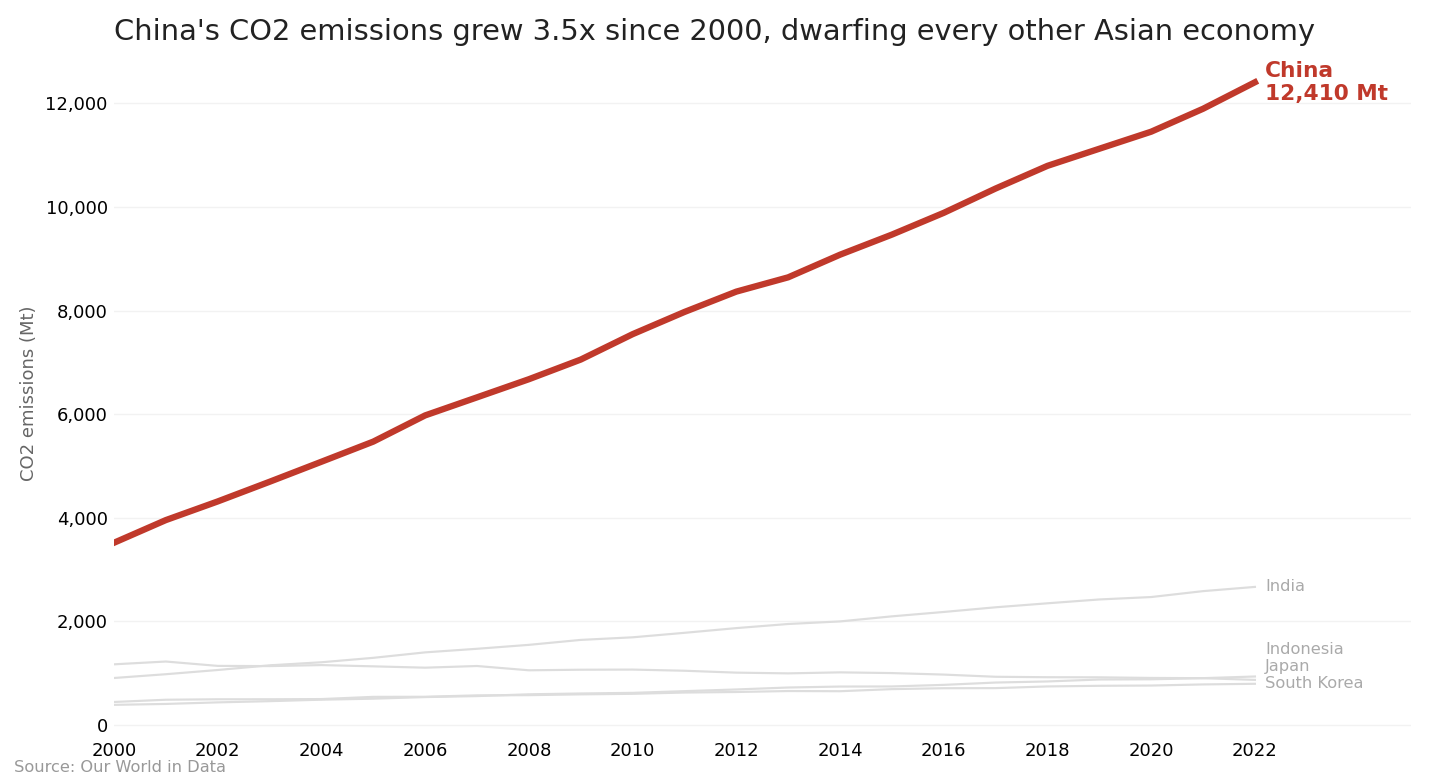

In [16]:
# Task — Multi-series line with highlight

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

HIGHLIGHT = 'China'          # the story we want to tell
HL_COLOR  = '#C0392B'        # highlight colour
GREY      = '#DDDDDD'        # context lines

# 1. Filter: all Asian countries
asia = df[df['Region'] == 'Asia'].sort_values(['Country', 'Year'])
print("Asian countries:", sorted(asia['Country'].unique()))

# 2. Numbers for the insight title (computed, not hard-coded)
hl = asia[asia['Country'] == HIGHLIGHT].set_index('Year')['CO2_Mt']
y0, y1 = hl.index.min(), hl.index.max()
growth = hl[y1] / hl[y0]
title = f"{HIGHLIGHT}'s CO2 emissions grew {growth:.1f}x since {y0}, dwarfing every other Asian economy"

# 3. Chart: grey context lines first, highlight on top
fig, ax = plt.subplots(figsize=(11, 6))

# end-of-line values for the grey countries, with labels nudged apart so they don't overlap
ends = {}
for country, g in asia.groupby('Country'):
    if country == HIGHLIGHT:
        continue
    ax.plot(g['Year'], g['CO2_Mt'], color=GREY, linewidth=1.2)
    ends[country] = g['CO2_Mt'].iloc[-1]

min_gap = 330                      # minimum vertical spacing between labels (Mt)
label_y, prev = {}, None
for country, v in sorted(ends.items(), key=lambda kv: kv[1]):
    prev = v if prev is None else max(v, prev + min_gap)
    label_y[country] = prev
for country, ly in label_y.items():
    ax.text(y1 + 0.2, ly, country, color='#AAAAAA', fontsize=9, va='center')

ax.plot(hl.index, hl.values, color=HL_COLOR, linewidth=3.5)

# 4. Direct label at the end of the highlighted line (no legend)
ax.text(y1 + 0.2, hl[y1], f"{HIGHLIGHT}\n{hl[y1]:,.0f} Mt",
        color=HL_COLOR, fontsize=12, fontweight='bold', va='center')

# 5. Clean styling: no borders, light gridlines, horizontal text
for s in ax.spines.values():
    s.set_visible(False)
ax.yaxis.grid(True, color='#F2F2F2')
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.set_ylabel('CO2 emissions (Mt)', color='#666666')
ax.set_title(title, loc='left', fontsize=16, color='#222222')
ax.set_xlim(y0, y1 + 3)
ax.set_xticks(range(y0, y1 + 1, 2))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
fig.text(0.01, 0.01, 'Source: Our World in Data', fontsize=9, color='#999999')

plt.tight_layout()
plt.show()
